# imports

In [ ]:
import geopandas as gpd
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import torch
import torch.nn as nn
from preprocess import get_data
from sklearn.feature_selection import mutual_info_classif
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder
from torch.utils.data import DataLoader, TensorDataset

In [21]:
new_df = get_data()
new_df

,VITESSE_MA,METEO_beau,METEO_chute de neige,METEO_couvert,METEO_grêle,METEO_pluie,METEO_pluie givrante,ETAT_ROUTE_humide,ETAT_ROUTE_mouillé,ETAT_ROUTE_route enneigée,ETAT_ROUTE_sèche,ETAT_ROUTE_verglacée,LUMIERE_inconnu,LUMIERE_jour,LUMIERE_nuit,HEURE_SIN,HEURE_COS,VICTIME
0,50.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,-0.866,-0.500,False
1,80.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.000,-1.000,False
2,50.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,-0.707,0.707,False
3,50.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.000,0.000,False
4,80.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,-0.866,-0.500,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
18586,50.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.259,-0.966,False
18587,120.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.707,0.707,False
18588,50.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.259,-0.966,False
18589,50.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.500,-0.866,False


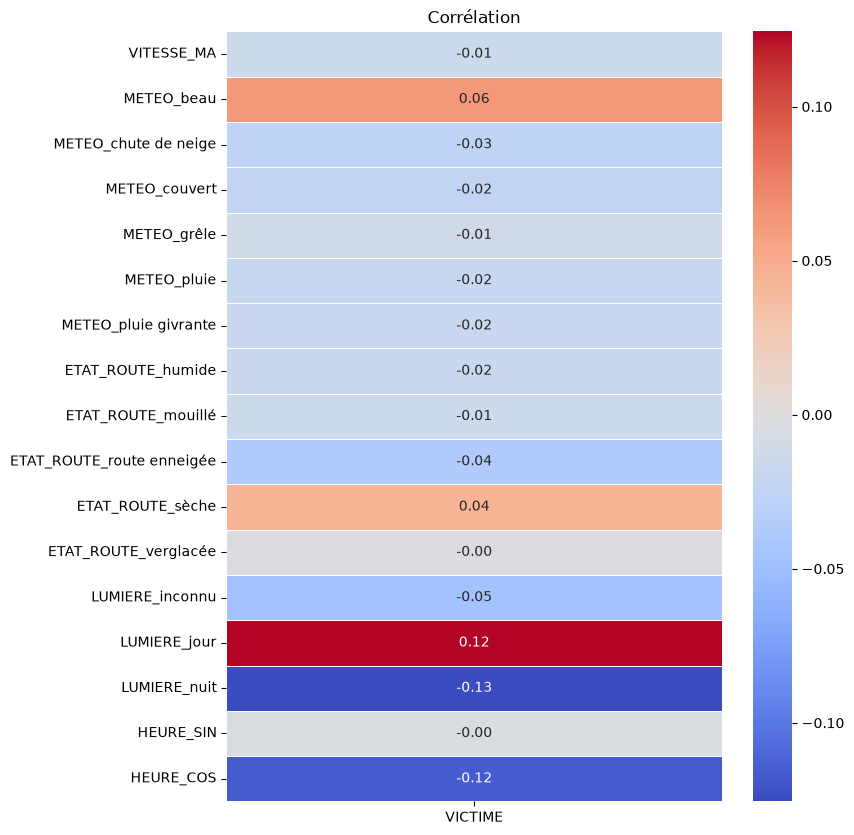

In [25]:
# Toutes les colonnes sauf les targets pour les lignes
feature_cols = [col for col in new_df.columns if col not in "VICTIME"]
corr = new_df.corr().loc[feature_cols, "VICTIME"]
corr = corr.to_frame(name="VICTIME")

plt.figure(figsize=(8, 10))
sns.heatmap(
    corr,
    annot=True,  # Affiche les valeurs numériques dans les cases
    cmap="coolwarm",  # Palette de couleurs (bleu = négatif, rouge = positif)
    fmt=".2f",  # Format des nombres (2 décimales)
    linewidths=0.5,  # Lignes de séparation entre les cellules
    cbar=True,  # Barre de couleur sur le côté
)
plt.title("Corrélation", fontsize=12)
plt.show()

# model

In [11]:
# hyperparameters
LEARNING_RATE = 1e-2  # try big gap, e.g. 1e-1
EPOCHS = 50
HIDDEN_SIZES = [128, 128, 128]
DROPOUT_RATE = 0.0
BATCH_SIZE = 1024  # try big gap, e.g. 512

# constants
INPUT_SIZE = new_df.shape[1] - 1
OUTPUT_SIZE = 1
ACCURACY_LOOP = 30

# Hyperparamters grids search
param_grid = {
    "hidden_sizes": [[30, 30], [64, 64], [128, 128]],
    "dropout_rate": [0.1, 0.2, 0.3, 0.5],
    "learning_rate": [1e-2, 1e-3, 1e-4, 1e-5],
    "batch_size": [64, 256, 512, 1024, 2048, 4096],
    "epochs": [300],
}


In [12]:
print(new_df.shape)
X_train, X_temp, y_train, y_temp = train_test_split(
    new_df.drop(columns=["VICTIME"]),
    new_df[["VICTIME"]],
    test_size=0.2,
    random_state=42,
)

X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.5, random_state=42
)

print(X_train.shape, y_train.shape)

train_dataloader = DataLoader(
    TensorDataset(
        torch.tensor(X_train.values, dtype=torch.float32),
        torch.tensor(y_train.values, dtype=torch.float32),
    ),
    batch_size=BATCH_SIZE,
    shuffle=True,
)

val_dataloader = DataLoader(
    TensorDataset(
        torch.tensor(X_val.values, dtype=torch.float32),
        torch.tensor(y_val.values, dtype=torch.float32),
    ),
    batch_size=BATCH_SIZE,
    shuffle=True,
)

test_dataloader = DataLoader(
    TensorDataset(
        torch.tensor(X_test.values, dtype=torch.float32),
        torch.tensor(y_test.values, dtype=torch.float32),
    ),
    batch_size=BATCH_SIZE,
    shuffle=True,
)


(14311, 18)
(11448, 17) (11448, 1)


In [13]:
class MLP(nn.Module):
    def __init__(self, input_size, hidden_sizes, output_size, dropout_rate):
        super(MLP, self).__init__()

        layers = []

        # input layer
        layers.append(nn.Linear(input_size, hidden_sizes[0]))
        layers.append(nn.ReLU())
        layers.append(nn.Dropout(dropout_rate))

        # hidden layers
        for i in range(len(hidden_sizes) - 1):
            layers.append(nn.Linear(hidden_sizes[i], hidden_sizes[i + 1]))
            layers.append(nn.ReLU())
            layers.append(nn.Dropout(dropout_rate))

        # output layer
        layers.append(nn.Linear(hidden_sizes[-1], output_size))

        # combine all layers
        self.model = nn.Sequential(*layers)

    def forward(self, x):  # type: ignore
        return self.model(x)


In [14]:
def train(dataloader, model, loss_fn, optimizer):
    model.train()
    train_loss = 0.0

    for X, y in dataloader:
        # Compute prediction error
        pred = model(X)
        loss = loss_fn(pred, y)
        train_loss += loss.item()

        # Backpropagation
        loss.backward()
        optimizer.step()
        optimizer.zero_grad()

    return train_loss / len(dataloader)


def test(dataloader, model, loss_fn):
    model.eval()
    test_loss = 0.0
    correct_labels = 0
    total_labels = 0

    with torch.no_grad():
        for X, y in dataloader:
            pred = model(X)
            loss = loss_fn(pred, y)

            predicted = pred >= 0.5
            targets = y == 1
            correct_labels += (predicted == targets).sum().item()
            total_labels += y.numel()
            test_loss += loss.item()

    accuracy = correct_labels / total_labels if total_labels > 0 else 0
    print(f"Test Accuracy: {accuracy * 100:.2f}%")

    true_positif = ((predicted == 1) & (targets == 1)).sum().item()
    false_positif = ((predicted == 1) & (targets == 0)).sum().item()
    true_negatif = ((predicted == 0) & (targets == 0)).sum().item()
    false_negatif = ((predicted == 0) & (targets == 1)).sum().item()

    print(f"True Positive: {true_positif}")
    print(f"False Positive: {false_positif}")
    print(f"True Negative: {true_negatif}")
    print(f"False Negative: {false_negatif}")

    precision = (
        true_positif / (true_positif + false_positif)
        if (true_positif + false_positif) > 0
        else 0
    )
    recall = (
        true_positif / (true_positif + false_negatif)
        if (true_positif + false_negatif) > 0
        else 0
    )
    f1_score = (
        2 * (precision * recall) / (precision + recall)
        if (precision + recall) > 0
        else 0
    )

    print(f"Precision: {precision:.4f}")
    print(f"Recall: {recall:.4f}")
    print(f"F1 Score: {f1_score:.4f}")

    return test_loss / len(dataloader), accuracy


In [15]:
model = MLP(INPUT_SIZE, HIDDEN_SIZES, OUTPUT_SIZE, DROPOUT_RATE)
optimizer = torch.optim.Adam(model.parameters(), lr=LEARNING_RATE)
loss_fn = nn.BCEWithLogitsLoss()

In [16]:
train_losses = []
validation_losses = []

for t in range(EPOCHS):
    print(f"epoch {t + 1}/{EPOCHS} ")

    train_loss = train(train_dataloader, model, loss_fn, optimizer)
    validation_loss, accuracy = test(val_dataloader, model, loss_fn)

    train_losses.append(train_loss)
    validation_losses.append(validation_loss)

    print(f"\t train loss: {train_loss:.4f}")
    print(f"\t validation loss: {validation_loss:.4f}")


epoch 1/50 
Test Accuracy: 51.08%
True Positive: 89
False Positive: 63
True Negative: 116
False Negative: 139
Precision: 0.5855
Recall: 0.3904
F1 Score: 0.4684
	 train loss: 0.9773
	 validation loss: 0.6915
epoch 2/50 
Test Accuracy: 51.57%
True Positive: 116
False Positive: 75
True Negative: 88
False Negative: 128
Precision: 0.6073
Recall: 0.4754
F1 Score: 0.5333
	 train loss: 0.6829
	 validation loss: 0.6948
epoch 3/50 
Test Accuracy: 43.47%
True Positive: 0
False Positive: 0
True Negative: 185
False Negative: 222
Precision: 0.0000
Recall: 0.0000
F1 Score: 0.0000
	 train loss: 0.6851
	 validation loss: 0.6896
epoch 4/50 
Test Accuracy: 43.47%
True Positive: 0
False Positive: 0
True Negative: 175
False Negative: 232
Precision: 0.0000
Recall: 0.0000
F1 Score: 0.0000
	 train loss: 0.6784
	 validation loss: 0.6806
epoch 5/50 
Test Accuracy: 43.47%
True Positive: 0
False Positive: 0
True Negative: 185
False Negative: 222
Precision: 0.0000
Recall: 0.0000
F1 Score: 0.0000
	 train loss: 0.67

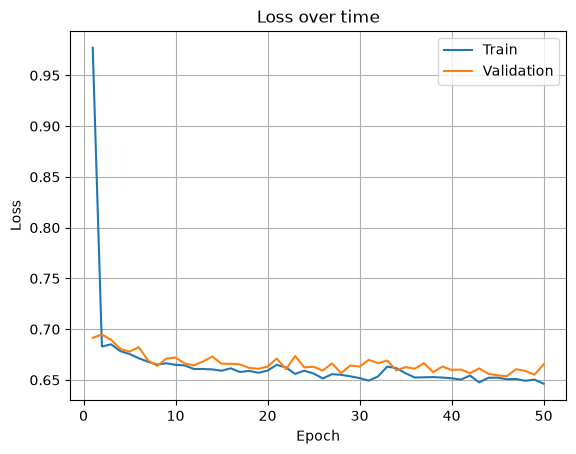

In [17]:
epoch_numbers = range(1, EPOCHS + 1)
plt.plot(epoch_numbers, train_losses, label="Train")
plt.plot(epoch_numbers, validation_losses, label="Validation")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Loss over time")
plt.legend()
plt.grid(True)
plt.show()

In [18]:
test(test_dataloader, model, loss_fn)

Test Accuracy: 62.57%
True Positive: 183
False Positive: 102
True Negative: 75
False Negative: 48
Precision: 0.6421
Recall: 0.7922
F1 Score: 0.7093


(0.6593605875968933, 0.6256983240223464)